# K-Means Clustering: Study Time and Exam Performance

This notebook demonstrates an end-to-end K-Means workflow. We will create a small student dataset, inspect the data, use the elbow and silhouette methods to choose the number of clusters, and interpret the resulting groups.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.style.use("seaborn-v0_8-whitegrid")

## 2. Create and inspect the dataset

The three simulated groups represent students with low, medium, and high study time. The exam scores are intentionally on a different scale, which makes feature standardisation important before clustering.

In [2]:
def create_student_group(size, study_hours, exam_score):
    hours = np.random.normal(study_hours, 0.65, size)
    scores = np.random.normal(exam_score, 5, size)
    return np.column_stack((hours, scores))


student_data = np.vstack([
    create_student_group(80, 2.5, 58),
    create_student_group(80, 5.5, 72),
    create_student_group(80, 8.5, 88),
])

students = pd.DataFrame(student_data, columns=["Study_Hours", "Exam_Score"])
students["Study_Hours"] = students["Study_Hours"].clip(0.5, 12).round(2)
students["Exam_Score"] = students["Exam_Score"].clip(0, 100).round(0).astype(int)
print(f"Number of students: {len(students)}")
display(students.head())
display(students.describe().round(2))

Number of students: 240


,Study_Hours,Exam_Score
0,2.82,57
1,2.41,60
2,2.92,65
3,3.49,55
4,2.35,54


,Study_Hours,Exam_Score
count,240.00,240.00
mean,5.51,72.68
std,2.58,13.24
min,0.80,48.00
25%,2.84,60.00
50%,5.62,72.00
75%,8.04,84.00
max,9.92,100.00


## 3. Visualise the raw data

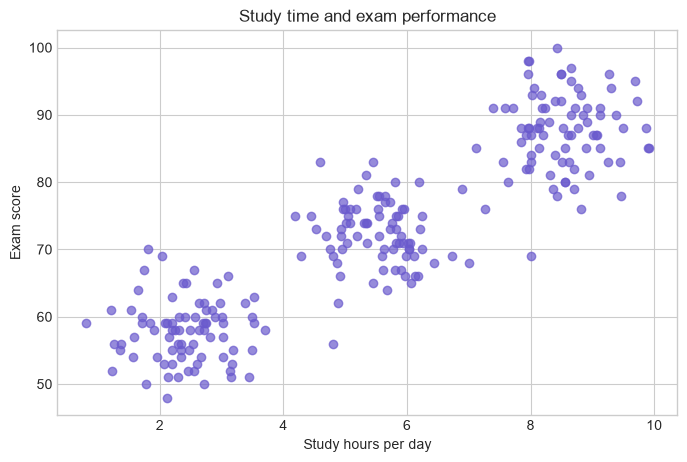

In [3]:
plt.figure(figsize=(8, 5))
plt.scatter(students["Study_Hours"], students["Exam_Score"], alpha=0.7, color="slateblue")
plt.title("Study time and exam performance")
plt.xlabel("Study hours per day")
plt.ylabel("Exam score")
plt.show()

## 4. Standardise the features

K-Means uses distances. StandardScaler puts both features on a comparable scale so that one feature does not dominate the result.

In [4]:
features = ["Study_Hours", "Exam_Score"]
scaler = StandardScaler()
X = scaler.fit_transform(students[features])

print("Scaled feature means:", X.mean(axis=0).round(3))
print("Scaled feature standard deviations:", X.std(axis=0).round(3))

Scaled feature means: [-0. -0.]
Scaled feature standard deviations: [1. 1.]


## 5. Choose the number of clusters

The elbow method looks for a bend in the within-cluster sum of squares (inertia). The silhouette score measures how well each sample fits its assigned cluster; higher values are better.

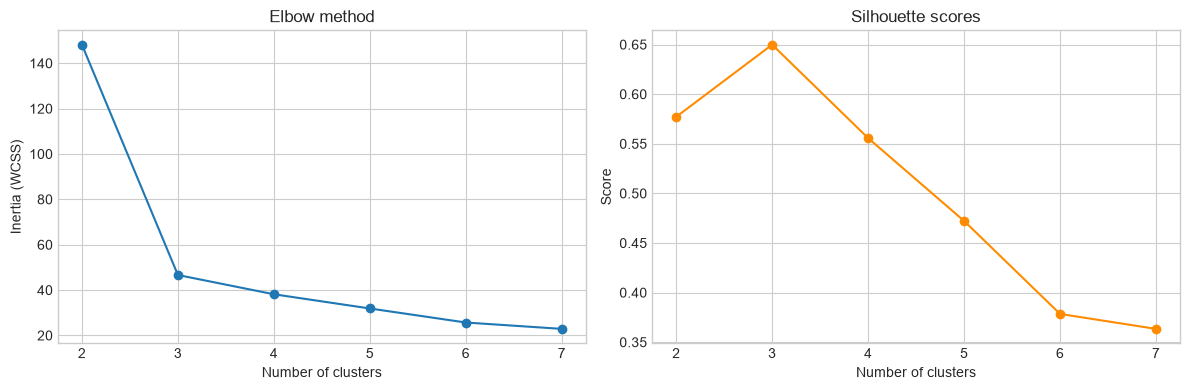

,Clusters,Inertia,Silhouette_Score
0,2,148.181,0.577
1,3,46.617,0.650
2,4,38.134,0.556
3,5,31.865,0.472
4,6,25.678,0.378
5,7,22.869,0.363


In [5]:
cluster_range = range(2, 8)
inertias = []
silhouette_scores = []

for cluster_count in cluster_range:
    model = KMeans(n_clusters=cluster_count, n_init=10, random_state=RANDOM_STATE)
    labels = model.fit_predict(X)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X, labels))

evaluation = pd.DataFrame({
    "Clusters": list(cluster_range),
    "Inertia": inertias,
    "Silhouette_Score": silhouette_scores,
})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(evaluation["Clusters"], evaluation["Inertia"], marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia (WCSS)")
axes[1].plot(evaluation["Clusters"], evaluation["Silhouette_Score"], marker="o", color="darkorange")
axes[1].set_title("Silhouette scores")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Score")
plt.tight_layout()
plt.show()

display(evaluation.round(3))

In [6]:
chosen_k = int(evaluation.loc[evaluation["Silhouette_Score"].idxmax(), "Clusters"])
print(f"Selected number of clusters: {chosen_k}")

Selected number of clusters: 3


## 6. Train K-Means and inspect the clusters

In [7]:
kmeans = KMeans(n_clusters=chosen_k, n_init=20, random_state=RANDOM_STATE)
students["Cluster"] = kmeans.fit_predict(X)

print(f"Final silhouette score: {silhouette_score(X, students['Cluster']):.3f}")
print("\nStudents in each cluster:")
display(students["Cluster"].value_counts().sort_index().rename("Students"))

Final silhouette score: 0.650

Students in each cluster:


Cluster
0    79
1    80
2    81
Name: Students, dtype: int64

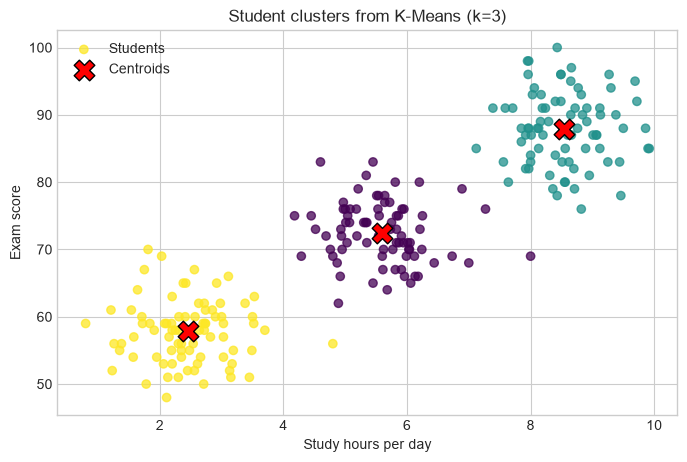

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(
    students["Study_Hours"],
    students["Exam_Score"],
    c=students["Cluster"],
    cmap="viridis",
    alpha=0.75,
    label="Students",
)

centres = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(centres[:, 0], centres[:, 1], marker="X", s=220, color="red", edgecolor="black", label="Centroids")
plt.title(f"Student clusters from K-Means (k={chosen_k})")
plt.xlabel("Study hours per day")
plt.ylabel("Exam score")
plt.legend()
plt.show()

## 7. Interpret and save the result

The profile below converts the cluster labels into useful real-world summaries. Cluster numbers are arbitrary; the averages are what give each group meaning.

In [9]:
cluster_profile = students.groupby("Cluster")[features].mean().round(2)
cluster_profile["Students"] = students["Cluster"].value_counts().sort_index()
display(cluster_profile.sort_values("Study_Hours"))

output_path = "student_clusters.csv"
students.to_csv(output_path, index=False)
print(f"Saved clustered data to {output_path}")

,Study_Hours,Exam_Score,Students
Cluster,,,
2,2.45,57.84,81
0,5.59,72.49,79
1,8.54,87.90,80


Saved clustered data to student_clusters.csv
